# Lab 02 – Linear Regression

Predict `House_Price` from the features in `houses.csv` with `LinearRegression` and `SGDRegressor`, then compare the two models on a held-out test set.

In [1]:
! pip install numpy pandas scikit-learn matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 2.4 MB/s  0:00:07m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 1.8 MB/s  0:00:06 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 2.3 MB/s  0:00:04 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 2.3 MB/s  0:00:04m0:00:0100:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 1.7 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 1.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 2.4 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 2.2 MB/s  0:00:15m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15/15 [matplotlib]5 [matplotlib]n]

[notice] A new release of pip is available:

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

DATA_PATH = Path("houses.csv")
RANDOM_STATE = 42
REFERENCE_YEAR = 2026  # fixed so "years since construction" is reproducible

## 1. Data processing

In [4]:
df = pd.read_csv(DATA_PATH, index_col=0)
print(df.shape)
df.head()

(1000, 8)


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


Replace `Year_Built` with the house's age, *years since construction*.

In [5]:
df["Years_Since_Built"] = REFERENCE_YEAR - df.pop("Year_Built")
df[["Years_Since_Built"]].describe()

,Years_Since_Built
count,1000.000000
mean,39.450000
std,20.632916
min,4.000000
25%,21.750000
50%,40.000000
75%,57.000000
max,76.000000


Min-Max normalize `Square_Footage` to $[0, 1]$: $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$.

Following the order in the requirements, the scaler is fit on the whole dataset before the train/test split.

In [6]:
df["Square_Footage"] = MinMaxScaler().fit_transform(df[["Square_Footage"]])
df[["Square_Footage"]].describe()

,Square_Footage
count,1000.000000
mean,0.514329
std,0.279252
min,0.000000
25%,0.277246
50%,0.524800
75%,0.744328
max,1.000000


## 2. Preparing the data for training

In [7]:
X = df.drop(columns="House_Price")
y = df["House_Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"train: {X_train.shape}, test: {X_test.shape}")

train: (800, 7), test: (200, 7)


## 3. Training the models

`SGDRegressor` is sensitive to feature scale: with the raw features (e.g. `Years_Since_Built` up to ~75 next to the $[0, 1]$ `Square_Footage`) its gradient steps blow up and it diverges. It is therefore wrapped in a pipeline with a `StandardScaler`, which is fit on the training set only. `LinearRegression` solves least squares in closed form and does not need it.

In [8]:
models = {
    "LinearRegression": LinearRegression(),
    "SGDRegressor": make_pipeline(StandardScaler(), SGDRegressor(random_state=RANDOM_STATE)),
}

for model in models.values():
    model.fit(X_train, y_train)

## 4. Evaluating the models

In [9]:
predictions = {name: model.predict(X_test) for name, model in models.items()}

for name, y_pred in predictions.items():
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name:<17} MSE = {mse:,.2f}   R² = {r2:.4f}")

LinearRegression  MSE = 101,434,798.51   R² = 0.9984
SGDRegressor      MSE = 101,508,326.93   R² = 0.9984


## 5. Visualizing the results

Actual vs. predicted prices for every house in the test set, one panel per model. Houses are sorted by actual price so the actual-price line is monotonic and deviations of the predictions stand out.

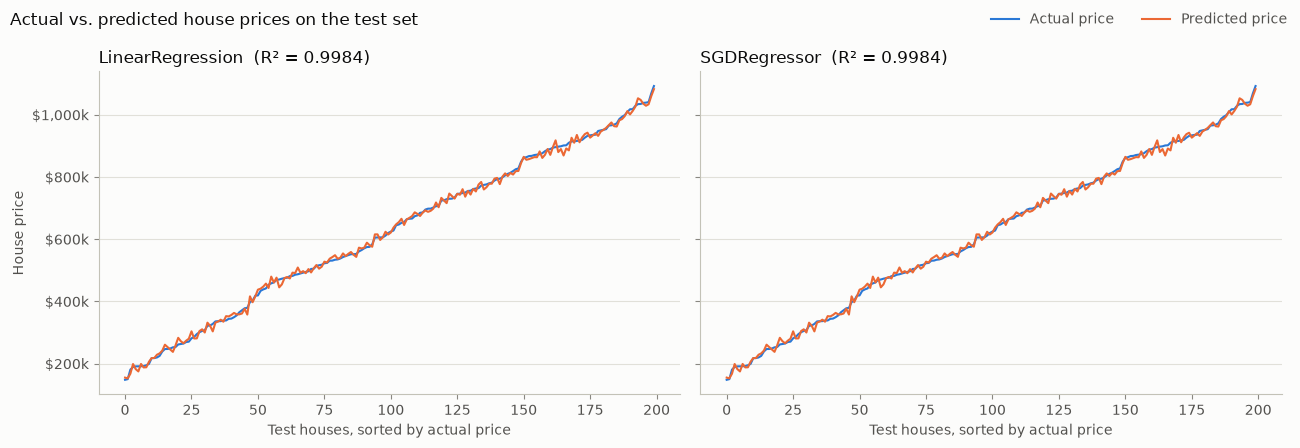

In [10]:
SURFACE, INK, INK_SECONDARY, MUTED, GRID, AXIS = (
    "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
)
ACTUAL_COLOR, PREDICTED_COLOR = "#2a78d6", "#eb6834"

order = np.argsort(y_test.to_numpy())
y_sorted = y_test.to_numpy()[order]
x = np.arange(len(y_sorted))

fig, axes = plt.subplots(1, len(predictions), figsize=(13, 4.5), sharey=True, facecolor=SURFACE)
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.set_facecolor(SURFACE)
    ax.plot(x, y_sorted, color=ACTUAL_COLOR, linewidth=1.5, label="Actual price")
    ax.plot(x, y_pred[order], color=PREDICTED_COLOR, linewidth=1.5, label="Predicted price")

    ax.set_title(f"{name}  (R² = {r2_score(y_test, y_pred):.4f})", color=INK, loc="left")
    ax.set_xlabel("Test houses, sorted by actual price", color=INK_SECONDARY)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v / 1e3:,.0f}k"))
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelcolor=INK_SECONDARY)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)

axes[0].set_ylabel("House price", color=INK_SECONDARY)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False, labelcolor=INK_SECONDARY)
fig.suptitle("Actual vs. predicted house prices on the test set", color=INK, x=0.01, ha="left")
fig.tight_layout()
plt.show()

## Conclusions

- Both models explain almost all of the variance in the test prices (R² close to 1): house price is close to a linear function of these features.
- Once the features are standardized, `SGDRegressor` converges to practically the same solution as the closed-form `LinearRegression`, so their MSE and R² are nearly identical.
- Without feature scaling, `SGDRegressor` diverges, which is why scaling matters for gradient-based models but not for ordinary least squares.